# Geo-embedding datasets: a tour and cloud-native access patterns

Several groups now publish **pre-computed geospatial embeddings** for the whole planet: AlphaEarth Foundations (AEF), Tessera, OlmoEarth, Clay, Earth Index, and the Major TOM embedding sets. They differ in the model behind them, in how much ground each vector covers, and above all in **how they are stored** (the two key objectives when deciding how to store embeddings are: reducing the total data volume and making it possible to fetch a small subset of the embeddings, since most workflows aren't applied at the global scale).

This notebook visits each dataset over the **same small area of interest (AOI)**, central Zurich, and shows the access pattern that fits its storage layout. For each access pattern we'll track bytes of data transferred to better inform tradeoff decisions. 

Everything here:

- runs on a laptop CPU (no GPU/cloud compute cluster),
- uses **anonymous access**: no cloud accounts, API keys or Earth Engine project,
- reads data **lazily**, fetching only the bytes the AOI needs whenever the storage layout allows it.

A companion notebook, [Analysis and fine-tuning with geo-embeddings](./geo_embeddings_02_analysis_and_fine_tuning.md), uses these access patterns for similarity search, clustering, change detection, classification and regression.

#### Tip: Running this notebook
Install the notebook dependencies with `uv sync --group notebooks` and open this file in Jupyter. The full run transfers roughly 0.6 GB, which is mostly a single Earth Index tile that we cache locally, and can takes a few minutes on a standard wifi connection.

## Kinds of embedding products

There are, broadly speaking, four main formats for embedding datasets, which determine the file formats, access patterns, and which analyses make sense. They differ mainly in how much ground one vector describes, its *spatial type* in the terms of the site's [model card](/model-card) and [glossary](/glossary).

| Kind | What one vector describes | Typical format | Access pattern | Examples |
|---|---|---|---|---|
| **Pixel embeddings** | One ~10 m pixel (often summarising a full year of observations) | Zarr, COG | Windowed array reads with xarray / rasterio | AEF, Tessera, OlmoEarth v1.3 |
| **Patch embeddings** | One model token: a small patch inside an image chip (e.g. 8 × 8 px, or 80 m, for Clay) | Zarr, COG (when published) | Same as pixel embeddings: a regular grid at patch resolution | Rarely published at global scale; produced by running a ViT encoder yourself |
| **Scene (chip) embeddings** | One whole image chip (hundreds of metres to a few km), pooled from its patch tokens | GeoParquet | Columnar queries with DuckDB / GeoPandas, filtered by bbox | Clay v1.5 (LGND), Earth Index, Major TOM |
| **On-demand models** | Whatever you feed them; no global product exists | Model weights | Run the encoder yourself (TorchGeo, Hugging Face) | Presto / Galileo, Prithvi, SatCLIP, GeoCLIP |


Pixel embeddings act like a deep multispectral raster, except that for each pixel, the array contains a learned representation of that position, rather than the raw sensor values. Pixel embeddings are best for high precision tasks, such as crop type mapping or field boundaries. Scene embeddings contain the learned representation from the entire scene and are best for tasks like object and scene recognition. For example, pixel embeddings would tell you exactly where there is alphalt and where there is grass in a scene, but a scene level embedding would tell you wether the scene contains a parking lot or an airplane runway (something you cannot tell by looking at the pixel embeddings on their own - since those can only tell you what is asphalt and what is grass).

Patch and scene embeddings come from the same models. A ViT-style encoder cuts its input chip into small patches, and outputs one vector (token) per patch. A scene embedding collapses that grid of tokens into a single vector, using either a summary CLS token or the mean of all patch tokens. Patch embeddings keep *where* things are inside the chip, which segmentation and fine-scale mapping need. However, they cost one vector per token, often hundreds to thousands of times the storage of the pooled vector, which is why producers almost always publish the pooled scene vector instead. The ViT-based scene products in this notebook (Clay, Earth Index, and most of the Major TOM sets) all started as a grid of patch embeddings that was pooled away.

## The datasets at a glance

| Dataset | Producer | Kind | Dims | Spatial unit | Years | Storage (anonymous) | License |
|---|---|---|---|---|---|---|---|
| [AlphaEarth Foundations](https://source.coop/tge-labs/aef-mosaic) | Google DeepMind (copy hosted by TGE Labs) | Pixel | 64, int8 | ~10 m | 2017–2025 annual | GeoZarr mosaic (EPSG:4326) and UTM COGs on Source Cooperative; also Earth Engine (needs an account) | CC-BY-4.0 |
| [Tessera v1.1](https://geotessera.org) | University of Cambridge | Pixel | 128, int8 + per-pixel scale | 10 m | 2017–2025 annual | One Zarr group per UTM zone on Source Cooperative; `.npy` tiles via the `geotessera` package | see geotessera.org |
| [OlmoEarth v1.3](https://source.coop/olmoearth/olmoearth-v1-3-embeddings) | Allen Institute for AI (Ai2) | Pixel | 128 (first 64 usable alone), int8 | 10 m | 2017–2025 annual (global for 2021–2025; earlier years being backfilled) | One Zarr group per UTM zone on Source Cooperative | [OlmoEarth Artifact License](https://source.coop/olmoearth/olmoearth-v1-3-embeddings/LICENSE.txt) |
| [Clay v1.5 – Sentinel-2](https://source.coop/clay/lgnd-clay-v1-5-sentinel-2-l2a) | LGND / Clay | Scene (chip) | 1024, float32 | 2.56 km Major TOM cell | June 2024, June 2025 | Hive-partitioned GeoParquet 1.1 with a bbox covering column | CC-BY-4.0 |
| [Earth Index v7](https://source.coop/earthgenome/earthindex-embeddings-v7) | Earth Genome | Scene (chip) | 384, float32 | Small overlapping chips | 2024, 2025-08 → 2026-08 | One GeoParquet per MGRS tile; STAC API for discovery | CC-BY-4.0 |
| [Major TOM 249k embeddings](https://huggingface.co/Major-TOM) | ESA Φ-lab and community | Scene (chip) | 256–1024 | 3.84 km chip | Mixed (2017–2023) | Parquet on Hugging Face, one file per model | varies (e.g. CC-BY-SA-4.0) |

A few notes:

- **Earth Index v1 is deprecated.** The original SoftCon-based [Earth Index embeddings](https://source.coop/earthgenome/earthindexembeddings) are kept as an archive; v7 uses a different model (SSL4EO-S12 DINO ViT-S/16), so vectors from the two must never be mixed.
- **OlmoEarth v1.3** (released October 2026) is a pixel product learned from Sentinel-1, Sentinel-2 and Landsat 8/9. It was trained with nested (Matryoshka) embeddings, so the first 64 of its 128 dimensions form a complete embedding on their own. Its license is not CC-BY, so review the terms before commercial use or redistribution.
- **Major TOM** publishes many embedding sets. The *Core-S2L2A-249k* family is particularly useful: the **same 248,719 Sentinel-2 chips** embedded with OlmoEarth-Base (an earlier, chip-level OlmoEarth model, not v1.3), Clay v1.5, SatCLIP, DINOv2, SigLIP and FarSLIP, which makes it a ready-made benchmark for comparing models.
- **Presto, Galileo, Prithvi and others** have no global pre-computed product that we know of. To use them you run the model yourself, which is out of scope for this "cheap and local" tour.

## Setup

We work over one Tessera-sized tile (0.1° × 0.1°, about 7.5 km × 11 km) covering central Zurich and the north end of the lake. All network reads go to public buckets, and anonymous access is configured per library below.

In [1]:
import json
import time
import urllib.request
import warnings
from pathlib import Path

import duckdb
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import rasterio
import xarray as xr
import zarr
from pyproj import Transformer
from rasterio.enums import Resampling
from rasterio.windows import Window
from scipy.spatial import cKDTree
from sklearn.decomposition import PCA
from zarr.errors import ZarrUserWarning

warnings.simplefilter('ignore', ZarrUserWarning)
# JPEG keeps notebook outputs small for image-like plots
%config InlineBackend.figure_formats = ['jpeg']
plt.rcParams['savefig.dpi'] = 80

# (min_lon, min_lat, max_lon, max_lat) in EPSG:4326
BBOX = (8.50, 47.30, 8.60, 47.40)
YEAR = 2024

CACHE = Path('tutorial_cache')
CACHE.mkdir(exist_ok=True)

SOURCE_COOP_S3 = 's3://us-west-2.opendata.source.coop'
# GDAL options for anonymous reads straight from the bucket (rasterio uses GDAL under the hood)
GDAL_S3 = dict(AWS_NO_SIGN_REQUEST='YES', AWS_REGION='us-west-2', GDAL_DISABLE_READDIR_ON_OPEN='EMPTY_DIR')

A few small helpers are used throughout:

- `duck_query` runs a DuckDB query in a fresh connection and reports how many bytes DuckDB actually read. A fresh connection makes sure nothing is served from DuckDB's cache.
- `record` keeps a log of every access, so we can compare the datasets at the end.
- `pca_rgb` projects embeddings onto their first three principal components, a standard quick look at embedding structure.

In [2]:
access_log = []


def record(dataset, pattern, seconds, megabytes, n_vectors, dims):
    access_log.append(dict(dataset=dataset, access_pattern=pattern, seconds=round(seconds, 1),
                           MB_read=round(megabytes, 1), vectors=n_vectors, dims=dims))


def duck_query(sql):
    """Run `sql` in a fresh DuckDB connection; return (DataFrame, MB read, seconds)."""
    con = duckdb.connect()
    con.sql("LOAD spatial; LOAD httpfs; SET s3_region='us-west-2';")
    profile = CACHE / 'duckdb_profile.json'
    con.sql("PRAGMA enable_profiling='json'")
    con.sql(f"PRAGMA profiling_output='{profile}'")
    t0 = time.perf_counter()
    df = con.sql(sql).df()
    seconds = time.perf_counter() - t0
    con.close()
    megabytes = json.loads(profile.read_text())['io']['total_bytes_read'] / 1e6
    return df, megabytes, seconds


def pca_rgb(X):
    """(n, d) embeddings -> (n, 3) colours in [0, 1] from the first three principal components."""
    pcs = PCA(n_components=3).fit_transform(X)
    lo, hi = np.percentile(pcs, [2, 98], axis=0)
    return np.clip((pcs - lo) / (hi - lo), 0, 1)


_ = duckdb.execute('INSTALL spatial; INSTALL httpfs;')

## 1. Pixel embeddings

### 1.1 AlphaEarth Foundations from the GeoZarr mosaic

The [AEF mosaic](https://source.coop/tge-labs/aef-mosaic) stitches Google's annual AEF embeddings into one global Zarr v3 array of shape `(time, band, y, x)`. It is sharded into 4096 × 4096 pixel shards with 256 × 256 inner chunks, so a small window touches only a handful of chunks. The [AEF xarray tutorial](./xarray_geospatial_embeddings_intro.md) covers the chunk and shard layout in detail; here we only need the basics.

Opening the store reads metadata only. Passing `chunks=None` keeps the arrays lazy without needing Dask.

In [3]:
aef = xr.open_zarr(f'{SOURCE_COOP_S3}/tge-labs/aef-mosaic/', storage_options={'anon': True},
                   consolidated=False, chunks=None)
aef

<xarray.Dataset> Size: 4PB
Dimensions:     (time: 9, band: 64, y: 1859584, x: 4009984)
Coordinates:
  * time        (time) int32 36B 2017 2018 2019 2020 2021 2022 2023 2024 2025
  * band        (band) StringDType() 1kB 'A00' 'A01' 'A02' ... 'A61' 'A62' 'A63'
  * y           (y) float64 15MB 83.69 83.69 83.69 ... -83.36 -83.36 -83.36
  * x           (x) float64 32MB -180.0 -180.0 -180.0 ... 180.2 180.2 180.2
Data variables:
    embeddings  (time, band, y, x) int8 4PB ...
Attributes: (12/15)
    proj:code:               EPSG:4326
    spatial:dimensions:      ['y', 'x']
    spatial:transform:       [8.983111749910169e-05, 0.0, -180.0, 0.0, -8.983...
    spatial:transform_type:  affine
    spatial:bbox:            [-180.0, -83.36280346631479, 180.2213438735178, ...
    spatial:shape:           [1859584, 4009984]
    ...                      ...
    geoemb:model:            https://developers.google.com/earth-engine/datas...
    geoemb:source_data:      https://source.coop/tge-labs/aef/v1/annual/
    geoemb:data_type:        int8
    geoemb:gsd:              8.983111749910169e-05
    geoemb:quantization:     {'method': 'signed_square', 'original_dtype': 'f...
    zarr_conventions:        [{'uuid': 'f17cb550-5864-4468-aeb7-f3180cfb622f'...

The store follows the [`geoemb:` Zarr convention](/standards), so the information needed to *use* the numbers correctly travels with the data. That includes the quantization scheme, which we need in a moment.

In [4]:
{k: v for k, v in aef.attrs.items() if k.startswith('geoemb:')}

{'geoemb:type': 'pixel',
 'geoemb:dimensions': 64,
 'geoemb:model': 'https://developers.google.com/earth-engine/datasets/catalog/GOOGLE_SATELLITE_EMBEDDING_V1_ANNUAL',
 'geoemb:source_data': 'https://source.coop/tge-labs/aef/v1/annual/',
 'geoemb:data_type': 'int8',
 'geoemb:gsd': 8.983111749910169e-05,
 'geoemb:quantization': {'method': 'signed_square',
  'original_dtype': 'float32',
  'quantized_dtype': 'int8',
  'formula': '(x / 127.5) ** 2 * sign(x)',
  'valid_range': [-127, 127],
  'nodata': -128}}

Selecting the AOI is ordinary label-based indexing. Note that `y` runs north to south, so the latitude slice goes from max to min. Nothing was downloaded when we opened the Zarr archive above, only when we access the data values themselves. It's recommended to check the expected data volume before fetching, especailly on a low-RAM machine. 

In [5]:
aef_lazy = aef['embeddings'].sel(time=YEAR, x=slice(BBOX[0], BBOX[2]), y=slice(BBOX[3], BBOX[1]))
print(f'shape {aef_lazy.shape}: {aef_lazy.nbytes / 1e6:.0f} MB as int8, '
      f'{aef_lazy.nbytes * 4 / 1e6:.0f} MB once converted to float32')

shape (64, 1114, 1113): 79 MB as int8, 317 MB once converted to float32


In [6]:
t0 = time.perf_counter()
aef_raw = aef_lazy.load()
seconds = time.perf_counter() - t0
record('AEF', 'GeoZarr window (xarray)', seconds, aef_raw.nbytes / 1e6,
       aef_raw.shape[1] * aef_raw.shape[2], 64)
print(f'loaded in {seconds:.1f} s')

loaded in 6.3 s


AEF values are stored as int8 using a **signed-square** quantization; `-128` marks no-data. After de-quantizing, each pixel's vector has unit length, which is worth verifying, since cosine similarity and dot product are only interchangeable when vectors are unit length.

In [7]:
def dequantize_signed_square(raw, nodata=-128):
    """Signed-square int8 -> float32 in [-1, 1]; `nodata` becomes NaN."""
    x = raw.values.astype(np.float32)
    out = np.sign(x) * (np.abs(x) / 127.5) ** 2
    out[raw.values == nodata] = np.nan
    return raw.copy(data=out)


aef_emb = dequantize_signed_square(aef_raw)
norms = np.linalg.norm(aef_emb.values, axis=0)
print(f'vector length: median {np.nanmedian(norms):.3f}, 1st-99th percentile '
      f'{np.nanpercentile(norms, 1):.3f}-{np.nanpercentile(norms, 99):.3f}; '
      f'no-data pixels: {np.isnan(norms).mean():.1%}')

vector length: median 1.000, 1st-99th percentile 0.996-1.005; no-data pixels: 0.0%


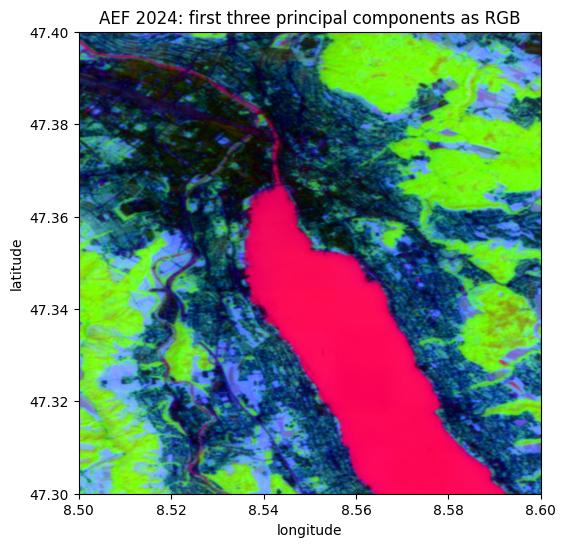

In [8]:
def pca_image(emb):
    """(band, y, x) embeddings -> (y, x, 3) PCA false-colour image; NaN pixels stay white."""
    bands, h, w = emb.shape
    X = emb.reshape(bands, -1).T
    valid = ~np.isnan(X).any(axis=1)
    img = np.ones((h * w, 3))
    img[valid] = pca_rgb(X[valid])
    return img.reshape(h, w, 3)


extent = (BBOX[0], BBOX[2], BBOX[1], BBOX[3])
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(pca_image(aef_emb.values), extent=extent)
ax.set_title(f'AEF {YEAR}: first three principal components as RGB')
ax.set_xlabel('longitude')
ax.set_ylabel('latitude')
plt.show()

Even without labels, the PCA view separates the lake, the dense city centre, residential areas, forest on the Zürichberg and Uetliberg ridges, and farmland. That is the first sign the embeddings carry useful information.

### 1.2 AEF as Cloud-Optimized GeoTIFFs: index first, then overviews

The same data is also published as [UTM-projected COGs](https://source.coop/tge-labs/aef), 8192 × 8192 pixels each. File names don't reveal their location, so the dataset ships a **STAC-GeoParquet index**. DuckDB can filter it on its `bbox` column and read only a few MB of a file describing every COG on Earth.

In [9]:
lon_c, lat_c = (BBOX[0] + BBOX[2]) / 2, (BBOX[1] + BBOX[3]) / 2
index_url = f'{SOURCE_COOP_S3}/tge-labs/aef/v1/annual/aef_index_stac_geoparquet.parquet'
cogs, megabytes, seconds = duck_query(f'''
    SELECT id, year(datetime AT TIME ZONE 'UTC') AS year, "proj:epsg" AS epsg, assets.data.href AS href,
           bbox.xmin < {lon_c} AND bbox.xmax > {lon_c} AND bbox.ymin < {lat_c} AND bbox.ymax > {lat_c} AS has_centre
    FROM '{index_url}'
    WHERE bbox.xmin < {BBOX[2]} AND bbox.xmax > {BBOX[0]} AND bbox.ymin < {BBOX[3]} AND bbox.ymax > {BBOX[1]}
''')
print(f'{len(cogs)} COGs intersect the AOI across all years; read {megabytes:.1f} MB of the index in {seconds:.1f} s')
cogs[cogs.year == YEAR]

18 COGs intersect the AOI across all years; read 4.1 MB of the index in 2.4 s


,id,year,epsg,href,has_centre
1,81255,2024,EPSG:32632,s3://us-west-2.opendata.source.coop/tge-labs/a...,True
9,81254,2024,EPSG:32632,s3://us-west-2.opendata.source.coop/tge-labs/a...,False


Two things to notice:

1. **The AOI straddles two files.** File boundaries are fixed by the producer, not by your area of interest. To look at a region centred on the AOI, we have to read from every file it touches and stitch the pieces together. That is exactly the work the Zarr mosaic in section 1.1 has already done for you.
2. **COGs have overviews, and for AEF they are meaningful.** Each overview pixel is the mean of the full-resolution vectors beneath it, re-normalized to unit length. Reading an overview is therefore a nearly free way to get *pooled* embeddings at 20 m, 40 m … 640 m.

The overviews are what make the COGs worth the extra effort. The Zarr mosaic has no overviews, so a coarse regional view from it means reading every full-resolution chunk. Below we read a 64 km × 64 km region **centred on our AOI** at 160 m resolution (1/16 of full resolution): we take the overlapping window from each COG, let GDAL serve it from the matching overview level, and paste the pieces into one grid. Two quirks to handle:

- The AEF COGs are stored "bottom-up" (positive y resolution, origin at the bottom-left), so the rows are flipped after reading.
- Every file here is in the same UTM zone (32N). A region crossing a zone boundary would also need reprojecting onto a common grid.

We read through GDAL's S3 driver (`/vsis3/`) with anonymous access. In our tests, larger overview reads through the `data.source.coop` HTTPS proxy were sometimes truncated, while the bucket's S3 endpoint was reliable.

In [10]:
def read_cogs_stitched(hrefs, bounds, res):
    """Mosaic AEF COGs onto one north-up int8 grid covering `bounds` (in the files' UTM CRS) at `res` metres."""
    left, bottom, right, top = bounds
    out = np.full((64, round((top - bottom) / res), round((right - left) / res)), -128, dtype=np.int8)
    footprints = []
    for href in hrefs:
        with rasterio.Env(**GDAL_S3), rasterio.open(href.replace('s3://', '/vsis3/')) as src:
            T = src.transform  # bottom-up file: T.f is the southern edge and T.e > 0
            f_left, f_bottom = T.c, T.f
            f_right, f_top = T.c + src.width * T.a, T.f + src.height * T.e
            footprints.append((f_left, f_bottom, f_right, f_top))
            il, ib, ir, it = max(left, f_left), max(bottom, f_bottom), min(right, f_right), min(top, f_top)
            if il >= ir or ib >= it:
                continue
            # where the overlap lands in the output grid...
            r0, r1 = round((top - it) / res), round((top - ib) / res)
            c0, c1 = round((il - left) / res), round((ir - left) / res)
            # ...and where it sits in the file (rows count up from the south)
            window = Window((il - T.c) / T.a, (ib - T.f) / T.e, (ir - il) / T.a, (it - ib) / T.e)
            data = src.read(window=window, out_shape=(src.count, r1 - r0, c1 - c0))
            out[:, r0:r1, c0:c1] = np.flip(data, axis=1)
    return out, footprints


RES, HALF = 160, 32_000  # 160 m pixels over a 64 km x 64 km region
to_utm32 = Transformer.from_crs('EPSG:4326', 'EPSG:32632', always_xy=True)
cx, cy = to_utm32.transform(lon_c, lat_c)
left, bottom = np.floor((cx - HALF) / RES) * RES, np.floor((cy - HALF) / RES) * RES
region = (left, bottom, left + 2 * HALF, bottom + 2 * HALF)
region_ll = Transformer.from_crs('EPSG:32632', 'EPSG:4326', always_xy=True).transform_bounds(*region)

region_cogs, _, _ = duck_query(f'''
    SELECT "proj:epsg" AS epsg, assets.data.href AS href FROM '{index_url}'
    WHERE year(datetime AT TIME ZONE 'UTC') = {YEAR}
      AND bbox.xmin < {region_ll[2]} AND bbox.xmax > {region_ll[0]} AND bbox.ymin < {region_ll[3]} AND bbox.ymax > {region_ll[1]}
''')
assert (region_cogs.epsg == 'EPSG:32632').all(), 'the region crosses a UTM zone boundary'

t0 = time.perf_counter()
overview, footprints = read_cogs_stitched(region_cogs.href, region, RES)
seconds = time.perf_counter() - t0
record('AEF', f'COG overviews (1/16 res.), {len(region_cogs)} files stitched', seconds, overview.nbytes / 1e6,
       overview.shape[1] * overview.shape[2], 64)
print(f'{len(region_cogs)} COGs stitched into a {overview.shape} grid in {seconds:.1f} s')

2 COGs stitched into a (64, 400, 400) grid in 6.1 s


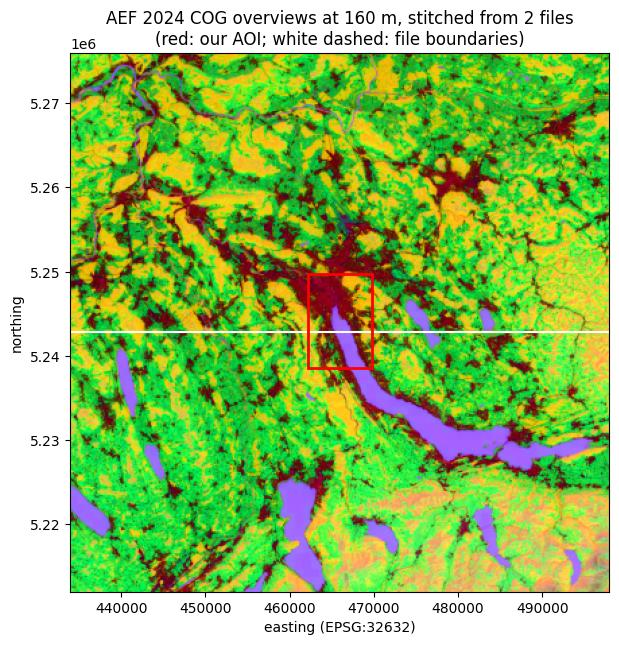

In [11]:
ov = dequantize_signed_square(xr.DataArray(overview)).values
x0, y0, x1, y1 = to_utm32.transform_bounds(*BBOX)

fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(pca_image(ov), extent=(region[0], region[2], region[1], region[3]))
for f_left, f_bottom, f_right, f_top in footprints:
    ax.add_patch(plt.Rectangle((f_left, f_bottom), f_right - f_left, f_top - f_bottom, fill=False,
                               edgecolor='white', linestyle='--', linewidth=1.5))
ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor='red', linewidth=2))
ax.set_xlim(region[0], region[2])
ax.set_ylim(region[1], region[3])
ax.set_title(f'AEF {YEAR} COG overviews at {RES} m, stitched from {len(footprints)} files\n'
             '(red: our AOI; white dashed: file boundaries)')
ax.set_xlabel('easting (EPSG:32632)')
ax.set_ylabel('northing')
plt.show()

The seam between the files is invisible in the embeddings themselves. AEF is computed consistently across file boundaries, so stitching is pure bookkeeping, but it is bookkeeping you have to get right: offsets, flipped rows, and UTM zones.

### 1.3 Tessera from per-UTM-zone Zarr

[Tessera](https://geotessera.org) embeddings are 128-dimensional and are learned from full Sentinel-1 and Sentinel-2 time series, so each pixel summarises a year of observations. They are mirrored on Source Cooperative as **one Zarr group per UTM zone**, in native UTM coordinates with no reprojection. The [`geotessera`](https://github.com/ucam-eo/geotessera) package offers a higher-level interface that downloads `.npy` tiles, but streaming from Zarr is the lazier option for small AOIs.

The root group documents the dataset with the same `geoemb:` convention as AEF. Tessera uses a different quantization, though: int8 values multiplied by a **per-pixel float32 scale** stored in a separate `scales` array.

In [12]:
TESSERA = f'{SOURCE_COOP_S3}/tessera/tessera/zarr/v1.1-dclimate'
root_attrs = zarr.open_group(TESSERA, mode='r', storage_options={'anon': True}).attrs.asdict()
{k: v for k, v in root_attrs.items() if k.startswith('geoemb:') and 'stretch' not in k}

{'geoemb:build_version': '0.10.3',
 'geoemb:data_type': 'int8',
 'geoemb:dimensions': 128,
 'geoemb:gsd': 10.0,
 'geoemb:model': 'https://geotessera.org/model/1.1',
 'geoemb:quantization': {'method': 'per_pixel_scale',
  'original_dtype': 'float32',
  'quantized_dtype': 'int8',
  'scale': {'array_name': 'scales', 'nodata': 'NaN', 'type': 'array'}},
 'geoemb:source_data': ['s3://sentinel-cogs',
  'https://datapool.asf.alaska.edu/RTC/OPERA-S1'],
 'geoemb:spatial_layout': 'utm_zones',
 'geoemb:type': 'pixel',
 'geoemb:landmask': False}

In [13]:
tessera = xr.open_zarr(f'{TESSERA}/utm32', storage_options={'anon': True}, consolidated=False, chunks=None)

# the AOI in UTM 32N; y is stored north -> south
xmin, ymin, xmax, ymax = Transformer.from_crs('EPSG:4326', 'EPSG:32632', always_xy=True).transform_bounds(*BBOX)
tess_lazy = tessera[['embeddings', 'scales']].sel(time=YEAR, x=slice(xmin, xmax), y=slice(ymax, ymin))
print(f"embeddings {tess_lazy['embeddings'].shape}: {tess_lazy['embeddings'].nbytes / 1e6:.0f} MB int8 "
      f"+ {tess_lazy['scales'].nbytes / 1e6:.0f} MB of scales")

t0 = time.perf_counter()
tess_raw = tess_lazy.load()
seconds = time.perf_counter() - t0
record('Tessera', 'Zarr window, UTM zone group (xarray)', seconds, tess_raw.nbytes / 1e6,
       tess_raw.sizes['y'] * tess_raw.sizes['x'], 128)
print(f'loaded in {seconds:.1f} s')

embeddings (128, 1116, 762): 109 MB int8 + 3 MB of scales


loaded in 8.9 s


In [14]:
tess_emb = tess_raw['embeddings'].astype(np.float32) * tess_raw['scales']  # NaN scale = no-data
norms = np.linalg.norm(tess_emb.values, axis=0)
print(f'vector length: median {np.nanmedian(norms):.1f} (not unit length - normalize before cosine similarity)')

vector length: median 11.3 (not unit length - normalize before cosine similarity)


### 1.4 OlmoEarth v1.3: per-UTM-zone Zarr with a 64-dimension shortcut

[OlmoEarth v1.3 embeddings](https://source.coop/olmoearth/olmoearth-v1-3-embeddings) use the same one-group-per-UTM-zone layout as Tessera, and the same `geoemb:` convention. Two details matter for cheap access:

- **Quantization** is signed-square, as for AEF (the store calls it `signed_power` with `power: 2`), so `dequantize_signed_square` works unchanged, but the vectors are *not* normalized; their length carries signal.
- **Matryoshka dimensions.** The array is chunked as `(1, 64, 256, 256)`, so bands 0–63 and 64–127 live in separate chunks. Because the first 64 dimensions are a complete embedding, reading only them **halves the download**.

In [15]:
OLMOEARTH = f'{SOURCE_COOP_S3}/olmoearth/olmoearth-v1-3-embeddings/embeddings.zarr'
olmo = xr.open_zarr(f'{OLMOEARTH}/utm32', storage_options={'anon': True}, consolidated=False, chunks=None)
{k: olmo.attrs[k] for k in ['geoemb:dimensions', 'geoemb:matryoshka_dims', 'geoemb:quantization', 'proj:code', 'license']}

{'geoemb:dimensions': 128,
 'geoemb:matryoshka_dims': [128, 64],
 'geoemb:quantization': {'method': 'signed_power',
  'power': 2.0,
  'formula': '(abs(q) / 127.5) ** 2.0 * sign(q)',
  'original_dtype': 'float32',
  'quantized_dtype': 'int8',
  'valid_range': [-127, 127],
  'nodata': -128},
 'proj:code': 'EPSG:32632',
 'license': {'url': 'https://data.source.coop/olmoearth/olmoearth-v1-3-embeddings/LICENSE.txt'}}

In [16]:
olmo_aoi = olmo['embeddings'].sel(time=YEAR, x=slice(xmin, xmax), y=slice(ymax, ymin))
for name, bands in [('first 64 dims', slice(0, 64)), ('all 128 dims', slice(None))]:
    t0 = time.perf_counter()
    raw = olmo_aoi.isel(band=bands).load()
    seconds = time.perf_counter() - t0
    record('OlmoEarth v1.3', f'Zarr window, UTM zone group, {name}', seconds, raw.nbytes / 1e6,
           raw.shape[1] * raw.shape[2], raw.shape[0])
    print(f'{name}: {raw.nbytes / 1e6:.0f} MB in {seconds:.1f} s')
olmo_raw = raw

olmo_emb = dequantize_signed_square(olmo_raw)
print(f'vector length (128-d): median {np.nanmedian(np.linalg.norm(olmo_emb.values, axis=0)):.2f}')

first 64 dims: 54 MB in 4.2 s


all 128 dims: 109 MB in 8.2 s


vector length (128-d): median 3.12


### 1.5 Putting pixel grids on a common footing

Tessera and OlmoEarth both use 10 m UTM grids anchored on multiples of 10 m, so within a zone their pixels **line up exactly** and can be stacked without resampling:

In [17]:
tess_aligned, olmo_aligned = xr.align(tess_raw['embeddings'], olmo_raw, join='exact')
print('Tessera and OlmoEarth share a pixel grid:', tess_aligned.shape[1:], '==', olmo_aligned.shape[1:])

Tessera and OlmoEarth share a pixel grid: (1116, 762) == (1116, 762)


AEF (EPSG:4326, ~0.00009°) sits on a different grid. Comparing or combining it with the UTM products requires resampling one onto the other, with two rules:

- **Use nearest-neighbour or averaging, never bilinear or cubic.** Interpolating between two embedding vectors produces a vector that may not correspond to anything real.
- **Resample while still quantized.** With nearest-neighbour, int8 values (and Tessera's scales) can be warped as-is, a quarter of the memory of warping float32 vectors.

In [18]:
import rioxarray  # noqa: F401  (registers the .rio accessor)

aef_grid = aef_raw.rio.write_crs('EPSG:4326')
tess_on_aef = xr.Dataset({
    'embeddings': tess_raw['embeddings'].rio.write_crs('EPSG:32632').rio.write_nodata(0)
                  .rio.reproject_match(aef_grid, resampling=Resampling.nearest),
    'scales': tess_raw['scales'].rio.write_crs('EPSG:32632').rio.write_nodata(np.nan)
              .rio.reproject_match(aef_grid, resampling=Resampling.nearest),
})
tess_on_aef_emb = tess_on_aef['embeddings'].astype(np.float32) * tess_on_aef['scales']
olmo_on_aef_emb = dequantize_signed_square(
    olmo_raw.rio.write_crs('EPSG:32632').rio.write_nodata(-128)
    .rio.reproject_match(aef_grid, resampling=Resampling.nearest))
print('Tessera and OlmoEarth on the AEF grid:', tess_on_aef_emb.shape, olmo_on_aef_emb.shape)

Tessera and OlmoEarth on the AEF grid: (128, 1114, 1113) (128, 1114, 1113)


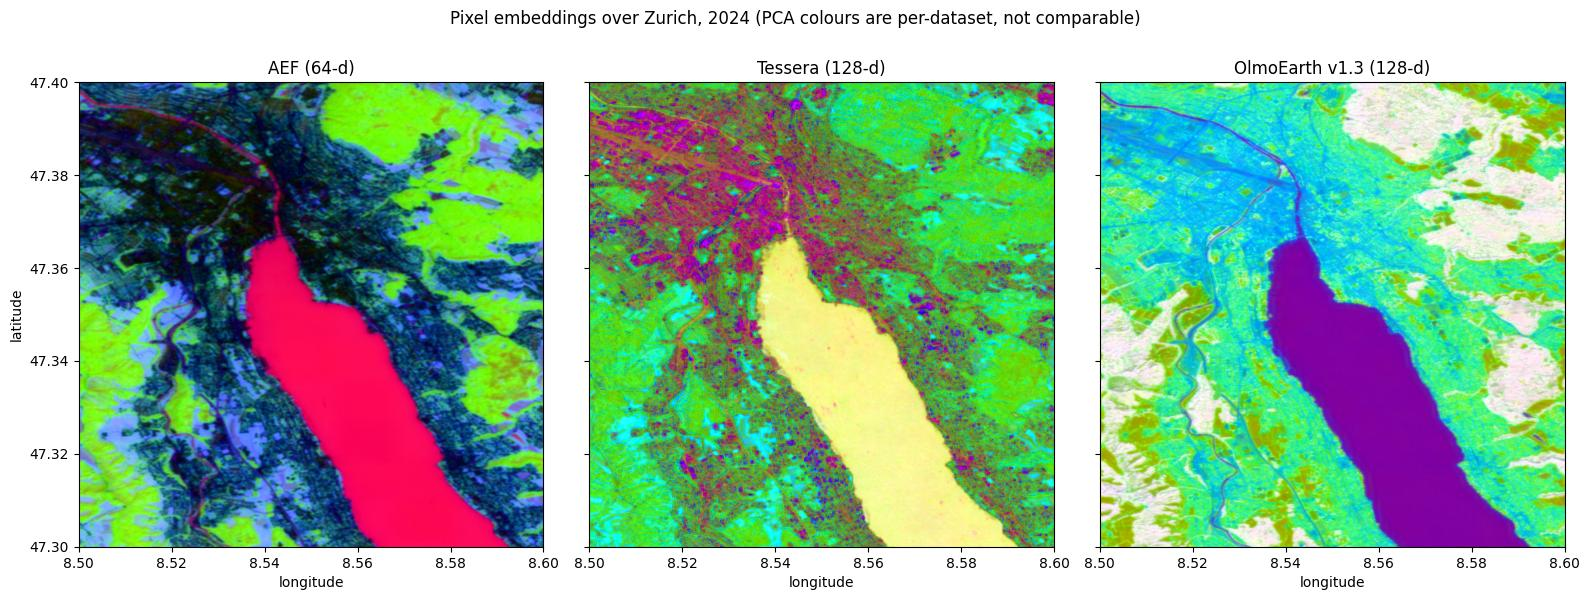

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6), sharey=True)
for ax, (name, emb) in zip(axes, [('AEF (64-d)', aef_emb), ('Tessera (128-d)', tess_on_aef_emb),
                                  ('OlmoEarth v1.3 (128-d)', olmo_on_aef_emb)]):
    ax.imshow(pca_image(emb.values), extent=extent)
    ax.set_title(name)
    ax.set_xlabel('longitude')
axes[0].set_ylabel('latitude')
plt.suptitle(f'Pixel embeddings over Zurich, {YEAR} (PCA colours are per-dataset, not comparable)')
plt.tight_layout()
plt.show()

## 2. Scene (chip) embeddings in GeoParquet

Scene-embedding products are tables: one row per footprint, with an array column holding the vector. Whether you can read *part* of such a table cheaply depends on how it was written:

- **Row groups and page statistics.** Parquet readers skip data whose min/max statistics rule it out. GeoParquet 1.1 adds a `bbox` **covering column** (plain `xmin/ymin/xmax/ymax` numbers) precisely so that spatial filters can use those statistics.
- **Spatial sorting.** Statistics only help if nearby features are stored together, for example along a Hilbert curve.
- **Column projection.** Parquet is columnar, so skipping the embedding column (usually >95% of the bytes) is always cheap.

### 2.1 Clay v1.5 (LGND): partitioned, sorted, with a bbox column

Each vector in the [LGND Clay embeddings](https://source.coop/clay/lgnd-clay-v1-5-sentinel-2-l2a) describes a 256 × 256 pixel chip. Inside the model, Clay's 8 × 8 pixel patches give a 32 × 32 grid of 1,024 patch tokens per chip, and the published vector pools them into one. The product is hive-partitioned by a 2-character **geohash**, then year and month, and follow the GeoParquet best practices: Hilbert-sorted rows, ~128 MB row groups and a bbox covering column. The geohash tells us which partition to read:

In [20]:
def geohash(lon, lat, precision=2):
    """Minimal geohash encoder: alternate longitude/latitude bisection bits, 5 bits per character."""
    alphabet = '0123456789bcdefghjkmnpqrstuvwxyz'
    ranges = {'lon': [-180.0, 180.0], 'lat': [-90.0, 90.0]}
    value = {'lon': lon, 'lat': lat}
    bits = ''
    for i in range(precision * 5):
        axis = 'lon' if i % 2 == 0 else 'lat'
        mid = sum(ranges[axis]) / 2
        upper = value[axis] >= mid
        bits += '1' if upper else '0'
        ranges[axis][0 if upper else 1] = mid
    return ''.join(alphabet[int(bits[i:i + 5], 2)] for i in range(0, len(bits), 5))


gh = geohash((BBOX[0] + BBOX[2]) / 2, (BBOX[1] + BBOX[3]) / 2)
clay_url = f'{SOURCE_COOP_S3}/clay/lgnd-clay-v1-5-sentinel-2-l2a/aggregated/geohash_l2={gh}/year=2025/month=06/*.parquet'
print(gh, clay_url)

u0 s3://us-west-2.opendata.source.coop/clay/lgnd-clay-v1-5-sentinel-2-l2a/aggregated/geohash_l2=u0/year=2025/month=06/*.parquet


The query filters on the `bbox` struct. DuckDB pushes that predicate down to the Parquet statistics, so the comparison below shows what each part of the query costs:

In [21]:
bbox_filter = f'bbox.xmin < {BBOX[2]} AND bbox.xmax > {BBOX[0]} AND bbox.ymin < {BBOX[3]} AND bbox.ymax > {BBOX[1]}'

_, mb_meta, s_meta = duck_query(f"SELECT chips_id FROM read_parquet('{clay_url}') WHERE {bbox_filter}")
clay_df, mb_full, s_full = duck_query(f'''
    SELECT chips_id, cell_id, datetime, embedding, ST_AsWKB(geometry) AS geometry
    FROM read_parquet('{clay_url}') WHERE {bbox_filter}
''')
record('Clay v1.5', 'GeoParquet + bbox filter (DuckDB)', s_full, mb_full, len(clay_df), 1024)
print(f'{len(clay_df)} chips; ids only: {mb_meta:.1f} MB in {s_meta:.1f} s; '
      f'with embeddings: {mb_full:.1f} MB in {s_full:.1f} s (the partition file is ~317 MB)')

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

20 chips; ids only: 3.0 MB in 4.4 s; with embeddings: 27.7 MB in 10.9 s (the partition file is ~317 MB)


In [22]:
clay = gpd.GeoDataFrame(clay_df.drop(columns='geometry'),
                        geometry=gpd.GeoSeries.from_wkb(clay_df['geometry'].map(bytes)), crs='EPSG:4326')
clay_X = np.stack(clay['embedding'].to_numpy())
clay[['chips_id', 'cell_id', 'datetime', 'geometry']].head()

,chips_id,cell_id,datetime,geometry
0,65e51954497cdb07a51d44c37b1b7eae,3b9831e05328791f86b447a85012c15c,2025-06-29 12:38:02.574000+02:00,"POLYGON ((8.51088 47.29944, 8.51088 47.32243, ..."
1,b2ea9b8198b13de64ba95edd81eb349e,4cc60a371103ba04623c0daf8b4373d9,2025-06-29 12:38:02.574000+02:00,"POLYGON ((8.54479 47.29944, 8.54479 47.32243, ..."
2,c272753dc40728f12d7f7f3d34c9f98b,f228403e21fa37ce109d7cdc5996d9be,2025-06-29 12:38:02.574000+02:00,"POLYGON ((8.6126 47.29944, 8.6126 47.32243, 8...."
3,8c047d76d52b73d078cf0d5d820b1ecb,2d7e18970b674077277a3f05be4856df,2025-06-29 12:38:02.574000+02:00,"POLYGON ((8.57869 47.29944, 8.57869 47.32243, ..."
4,c8aee50fd5007a56ddeb2eb574314a4b,af69b4008227f8b5c44f783861461256,2025-06-29 12:38:02.574000+02:00,"POLYGON ((8.58274 47.32243, 8.58274 47.34543, ..."


The query returned ~26 MB of a ~317 MB partition file. The bbox statistics let DuckDB skip most of the file, and Hilbert ordering means the matching rows sit close together.

### 2.2 Earth Index v7: STAC discovery, and a file you have to download whole

Earth Genome publishes a [STAC API](https://stac.earthgenome.org) for Earth Index, so we can *discover* the right file by bounding box instead of guessing tile names. A plain HTTP request is enough:

In [23]:
search = (f'https://stac.earthgenome.org/search?collections=ssl4eo_yearly_embeddings'
          f'&bbox={",".join(map(str, BBOX))}&limit=10')
items = json.load(urllib.request.urlopen(search))['features']
for item in items:
    print(item['id'], item['properties']['grid:code'], item['assets']['embeddings']['href'])

32TMT_2025-01-01_2026-01-01 MGRS-32TMT https://ei-ssl4eo-embeddings.s3.amazonaws.com/32TMT_2025-01-01_2026-01-01.parquet
32TMT_2024-01-01_2025-01-01 MGRS-32TMT https://ei-ssl4eo-embeddings.s3.amazonaws.com/32TMT_2024-01-01_2025-01-01.parquet


The STAC assets point at Earth Genome's own bucket; the same files are mirrored on Source Cooperative under `earthgenome/earthindex-embeddings-v7/`, named by MGRS tile and date range. We use the mirror below.

Each Earth Index file also carries its STAC Item **inside the Parquet footer** (under the `emb` key), following the [best practice of storing STAC metadata in GeoParquet](/bestpractices). Reading a footer costs one small range request, and it tells us the model, the preprocessing and even the energy used to compute the tile:

In [24]:
import pyarrow.fs as pafs

EI_KEY = f'earthgenome/earthindex-embeddings-v7/32TMT_{YEAR}-01-01_{YEAR + 1}-01-01.parquet'
s3 = pafs.S3FileSystem(anonymous=True, region='us-west-2')
ei_meta = pq.ParquetFile(f'us-west-2.opendata.source.coop/{EI_KEY}', filesystem=s3).metadata
stac_item = json.loads(ei_meta.metadata[b'emb'])
props = stac_item['properties']
print(f"{ei_meta.num_rows:,} rows in {ei_meta.num_row_groups} row group(s)")
print(props['description'])
print({k: props[k] for k in ['emb:runtime_parameters', 'emb:quantization', 'emb:energy']})

234,161 rows in 1 row group(s)
Chip-level embeddings from SSL4EO-S12 DINO ViT-S/16 over a Sentinel-2 temporal composite tile
{'emb:runtime_parameters': {'bands': ['B01', 'B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08', 'B8A', 'B09', 'B10', 'B11', 'B12'], 'chip_size': 224, 'stride': 112, 'emb:fit_for_use': ['similarity', 'retrieval', 'classification', 'clustering', 'segmentation']}, 'emb:quantization': {'method': 'none', 'original_dtype': 'float32', 'quantized_dtype': 'float32'}, 'emb:energy': {'device_type': 'gpu', 'energy_kwh': 0.004561491124353036, 'inference_duration_s': 347.81, 'avg_power_w': 47.2, 'max_power_w': 75.2, 'name': 'NVIDIA L4', 'instance_type': 'g2-standard-16', 'platform': 'gcp'}}


That footer also explains why this file is expensive to subset: **a single row group, no bbox covering column, and WKB point geometries without usable statistics.** Column projection still works, so finding the chips inside the AOI costs only ~3 MB, but their embeddings live in one ~334 MB column chunk that has to be read in full:

In [25]:
ei_url = f'{SOURCE_COOP_S3}/{EI_KEY}'
point_filter = (f'ST_X(geometry) BETWEEN {BBOX[0]} AND {BBOX[2]} '
                f'AND ST_Y(geometry) BETWEEN {BBOX[1]} AND {BBOX[3]}')
ei_ids, mb_ids, s_ids = duck_query(f"SELECT id FROM read_parquet('{ei_url}') WHERE {point_filter}")
print(f'{len(ei_ids)} Earth Index chips in the AOI; locating them read {mb_ids:.1f} MB in {s_ids:.1f} s')

1626 Earth Index chips in the AOI; locating them read 2.9 MB in 2.8 s


When a dataset can't be subset remotely, the cheap move is to **download the file once, cache it, and query the local copy** from then on. Source Cooperative has no egress fees for anonymous users, and a local Parquet file makes every later query nearly instant.

In [26]:
ei_local = CACHE / Path(EI_KEY).name
if ei_local.exists():
    print(f'using the cached copy in {ei_local}')
else:
    t0 = time.perf_counter()
    pafs.copy_files(f'us-west-2.opendata.source.coop/{EI_KEY}', str(ei_local.resolve()),
                    source_filesystem=s3, destination_filesystem=pafs.LocalFileSystem())
    seconds = time.perf_counter() - t0
    record('Earth Index v7', 'whole-tile download, then local query', seconds,
           ei_local.stat().st_size / 1e6, len(ei_ids), 384)
    print(f'downloaded {ei_local.stat().st_size / 1e6:.0f} MB in {seconds:.1f} s')

ei_df, _, s_local = duck_query(f'''
    SELECT id, embedding, ST_AsWKB(geometry) AS geometry
    FROM read_parquet('{ei_local}') WHERE {point_filter}
''')
ei = gpd.GeoDataFrame(ei_df.drop(columns='geometry'),
                      geometry=gpd.GeoSeries.from_wkb(ei_df['geometry'].map(bytes)), crs='EPSG:4326')
ei_X = np.stack(ei['embedding'].to_numpy())
xy = ei.to_crs('EPSG:32632').get_coordinates().to_numpy()
spacing = np.median(cKDTree(xy).query(xy, k=2)[0][:, 1])
print(f'local AOI query: {s_local:.2f} s for {len(ei)} chips, whose centres are ~{spacing:.0f} m apart')

downloaded 337 MB in 99.3 s


local AOI query: 1.25 s for 1626 chips, whose centres are ~201 m apart


### 2.3 Major TOM embeddings on Hugging Face

The [Major TOM](https://huggingface.co/Major-TOM) embedding sets are Parquet files on the Hugging Face Hub. DuckDB reads them directly with `hf://` paths, without `git clone` or downloading the dataset. These files are also written as a single row group, so the useful trick is **column projection**: footprint columns for all 248,719 chips cost a few MB, while the 768-dimensional OlmoEarth embeddings in the same file are ~765 MB.

In [27]:
mt_url = 'hf://datasets/Major-TOM/Core-S2L2A-249k-OlmoEarth-Base/OlmoEarth_Base_crop_384x384.parquet'
mt, megabytes, seconds = duck_query(f"SELECT grid_cell, centre_lat, centre_lon, timestamp FROM '{mt_url}'")
record('Major TOM 249k (OlmoEarth)', 'column projection only (DuckDB, hf://)', seconds, megabytes, 0, 768)
print(f'{len(mt):,} chip footprints in {megabytes:.1f} MB, {seconds:.1f} s')

lat0, lon0 = (BBOX[1] + BBOX[3]) / 2, (BBOX[0] + BBOX[2]) / 2
mt['km_from_aoi'] = 111 * np.hypot(mt.centre_lat - lat0, (mt.centre_lon - lon0) * np.cos(np.radians(lat0)))
mt.nsmallest(3, 'km_from_aoi')

248,719 chip footprints in 5.0 MB, 2.9 s


,grid_cell,centre_lat,centre_lon,timestamp,km_from_aoi
191736,528U_63R,47.470486,8.428637,20220320T102639,16.191660
191086,525U_63R,47.201050,8.385319,20200913T101629,20.657518
191737,528U_66R,47.470257,8.827209,20170328T102021,24.754810


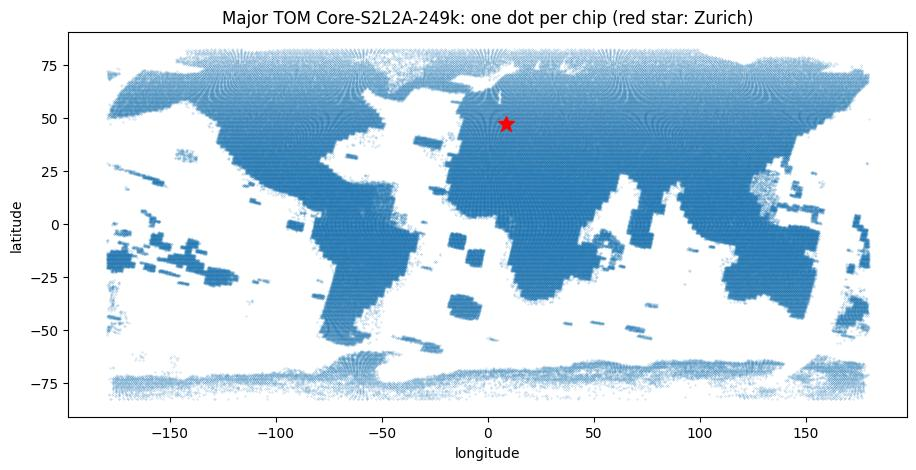

In [28]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.scatter(mt.centre_lon, mt.centre_lat, s=0.05, c='tab:blue', alpha=0.5, rasterized=True)
ax.plot(lon0, lat0, 'r*', markersize=12)
ax.set_title('Major TOM Core-S2L2A-249k: one dot per chip (red star: Zurich)')
ax.set_xlabel('longitude')
ax.set_ylabel('latitude')
ax.set_aspect('equal')
plt.show()

The nearest chip is ~16 km from our AOI. The 249k set is a **global sample**, not wall-to-wall coverage, which makes it the wrong tool for mapping Zurich and an excellent one for comparing models. Because every model in the family embedded exactly the same chips, the companion notebook downloads two of these files and compares two encoders trained with very different objectives (OlmoEarth-Base and SatCLIP's image encoder).

## 3. Comparing the datasets over Zurich

Every access above was logged. Here they are side by side. `MB_read` is the bytes DuckDB read from storage for the Parquet queries, and the decoded array size for array reads; Zarr chunks are compressed, so those transfers can be somewhat smaller.

In [29]:
pd.DataFrame(access_log)

,dataset,access_pattern,seconds,MB_read,vectors,dims
0,AEF,GeoZarr window (xarray),6.3,79.4,1239882,64
1,AEF,"COG overviews (1/16 res.), 2 files stitched",6.1,10.2,160000,64
2,Tessera,"Zarr window, UTM zone group (xarray)",8.9,112.3,850392,128
3,OlmoEarth v1.3,"Zarr window, UTM zone group, first 64 dims",4.2,54.4,850392,64
4,OlmoEarth v1.3,"Zarr window, UTM zone group, all 128 dims",8.2,108.9,850392,128
5,Clay v1.5,GeoParquet + bbox filter (DuckDB),10.9,27.7,20,1024
6,Earth Index v7,"whole-tile download, then local query",99.3,337.4,1626,384
7,Major TOM 249k (OlmoEarth),"column projection only (DuckDB, hf://)",2.9,5.0,0,768


And here is what each product "sees" over the same AOI. Scene products are drawn as their chip footprints or centres; colours again come from a per-dataset PCA, so compare patterns rather than colours.

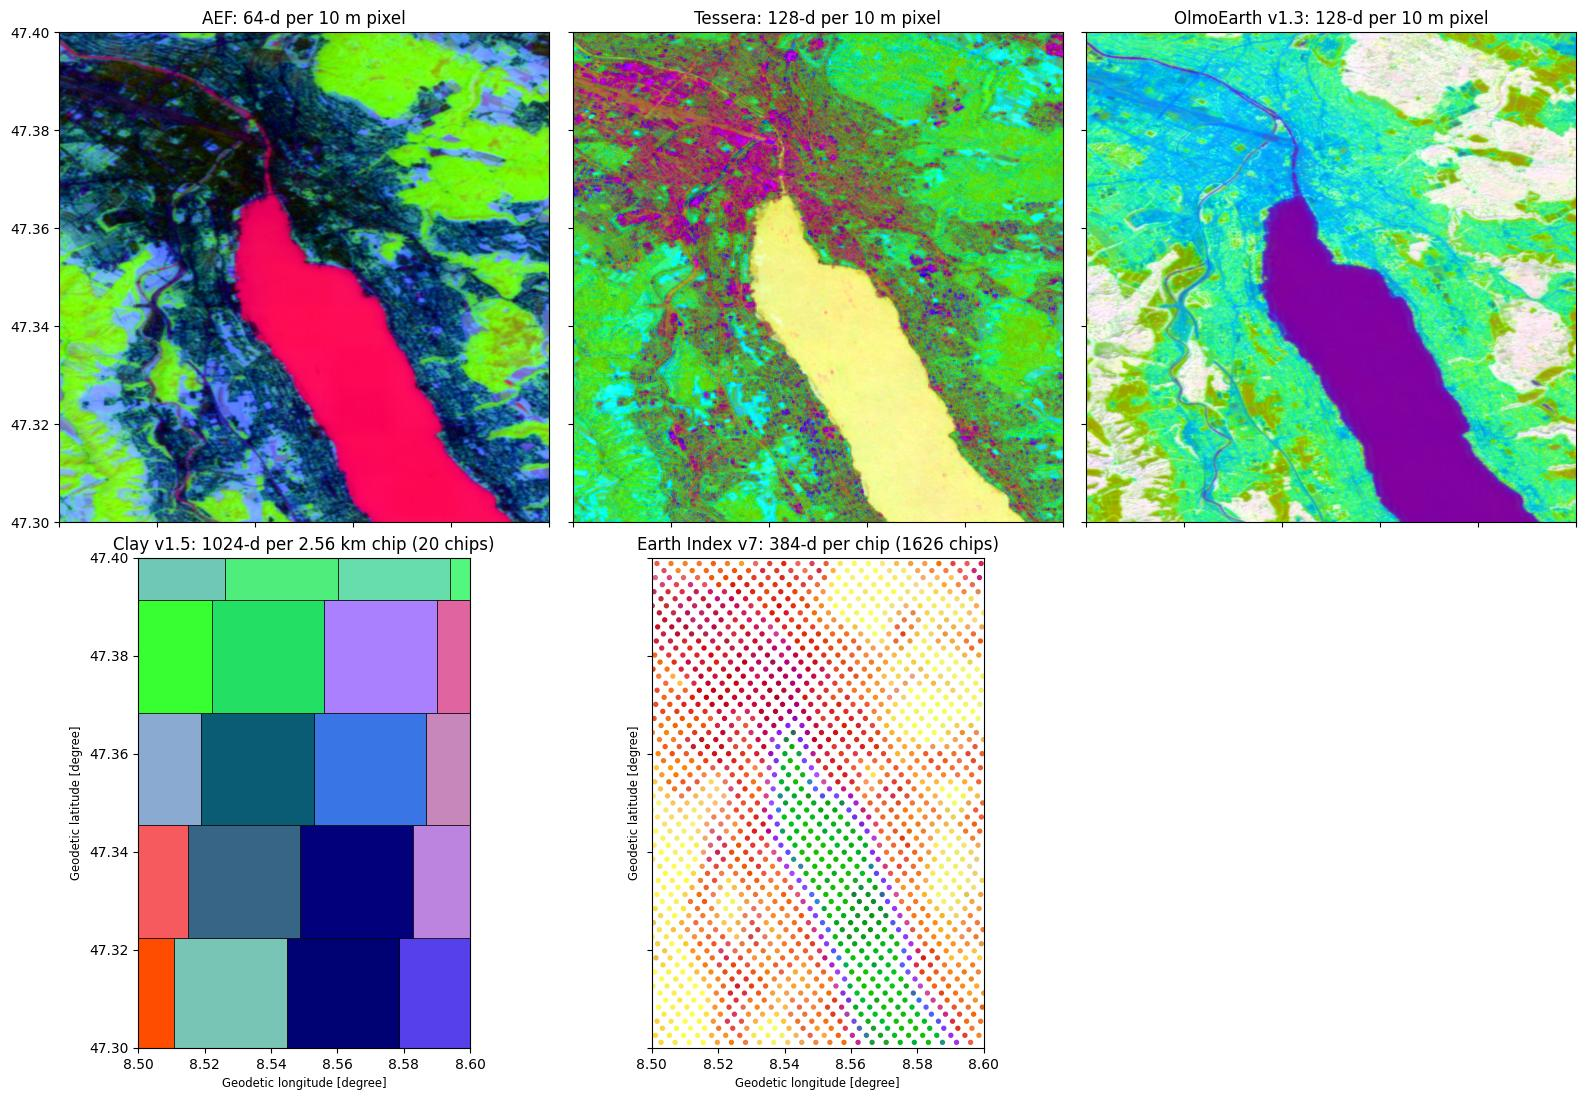

In [30]:
fig, axes = plt.subplots(2, 3, figsize=(16, 11), sharex=True, sharey=True)
axes = axes.ravel()
for ax, (name, emb) in zip(axes, [('AEF: 64-d', aef_emb), ('Tessera: 128-d', tess_on_aef_emb),
                                  ('OlmoEarth v1.3: 128-d', olmo_on_aef_emb)]):
    ax.imshow(pca_image(emb.values), extent=extent)
    ax.set_title(f'{name} per 10 m pixel')
clay.plot(ax=axes[3], color=pca_rgb(clay_X), edgecolor='k', linewidth=0.5)
axes[3].set_title(f'Clay v1.5: 1024-d per 2.56 km chip ({len(clay)} chips)')
ei.plot(ax=axes[4], color=pca_rgb(ei_X), markersize=8)
axes[4].set_title(f'Earth Index v7: 384-d per chip ({len(ei)} chips)')
axes[5].axis('off')
for ax in axes[:5]:
    ax.set_xlim(BBOX[0], BBOX[2])
    ax.set_ylim(BBOX[1], BBOX[3])
plt.tight_layout()
plt.show()

## 4. Rules of thumb for cheap, low-RAM access

1. **Look at the layout before the data.** Shards and chunks (Zarr), tiles and overviews (COG), row groups, sort order and covering columns (GeoParquet) decide whether a small read is possible at all.
2. **Check `nbytes` before `.load()`.** Lazy xarray objects and DuckDB `EXPLAIN ANALYZE` (or the profiler, as in `duck_query`) tell you what a read will cost before you pay it.
3. **Stay quantized as long as possible.** int8 is a quarter the size of float32. Subset, resample and cache in int8, and de-quantize just before the math.
4. **Project columns.** Footprints and ids are cheap; embedding columns are not. Find *where* first, then fetch *what*.
5. **Read only the dimensions you need.** OlmoEarth's Matryoshka layout stores the first 64 dimensions in their own chunks, which halves the download.
6. **Use pooled overviews for coarse work.** AEF's COG overviews give you averaged embeddings at 20–640 m almost for free.
7. **Cache once, query locally.** When a file can't be subset (Earth Index, Major TOM), download it once. When it can, save the AOI subset so later runs never touch the network.
8. **Normalize before comparing.** AEF is unit length; Tessera, OlmoEarth, Clay, Earth Index and the Major TOM sets are not.

## Next steps

The companion notebook, [Analysis and fine-tuning with geo-embeddings](./geo_embeddings_02_analysis_and_fine_tuning.md), puts these access patterns to work. It picks a different AOI for each task: greenhouses in Almería for similarity search and clustering, a 2023 wildfire in Greece for change detection, farmland in western Kenya for land-cover classification and a small fine-tuned head, Kakamega Forest for canopy-height regression, and the Major TOM 249k set for a global model comparison.